In [1]:
import pandas as pd


df = pd.read_csv('Online_Retail.csv', encoding='latin-1')
line_first = len(df)
print(df.shape)
print(df.info())

df.head()

(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [2]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [4]:
df[df['Quantity'] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,12/9/2011 9:57,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,12/9/2011 10:28,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,12/9/2011 11:57,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,12/9/2011 11:58,1.25,17315.0,United Kingdom


In [1]:
df['CustomerID'].nunique()

NameError: name 'df' is not defined

In [6]:
df['Country'].nunique()

38

In [7]:
df['InvoiceDate'].max()

'9/9/2011 9:52'

In [8]:
df['InvoiceDate'].min()

'1/10/2011 10:04'

In [2]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate']) #преобразуем в дату колону InvoiceDate
df = df.dropna(subset=['CustomerID']) # убираем клиентов без ID
df = df.drop_duplicates() 

#df = df[df['Quantity'] > 0] # убираем возвраты
df['CustomerID'] = df['CustomerID'].astype(int) # преобразуем в целое число ID
df['TotalPrice'] = df['UnitPrice'] * df['Quantity'] # добавляе столбец выручка

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  object        
 1   StockCode    401604 non-null  object        
 2   Description  401604 non-null  object        
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[ns]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  int64         
 7   Country      401604 non-null  object        
 8   TotalPrice   401604 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(4)
memory usage: 30.6+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Решения по очистке данных

1. Строки без CustomerID удалены (135 080 строк, ~25%).
   Обоснование: проект анализирует покупательское поведение
   (повторные покупки, сегменты), без идентификатора клиента
   такие строки бесполезны. При этом ~0,42% выручки в этих строках
   учитываем это ограничение в выводах.
2. Дубликаты удалены (5 268 строк). Полные повторы записей —
   вероятная ошибка выгрузки, оставлять их значит завышать метрики.
3. Возвраты (Quantity < 0) НЕ удаляем, они снижают выручку
   и являются частью реального поведения клиентов.


In [3]:
# 1. Переименовываем колонку, чтобы не резать глаз
df = df.rename(columns={'TotalPrice': 'TotalPrice_old'})

# 2. Считаем выручку заново: Quantity * UnitPrice — это сразу учитывает возвраты
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# 3. Смотрим, насколько отличаются старая и новая выручка
old_rev = df['TotalPrice_old'].sum()
new_rev = df['TotalPrice'].sum()
print(f"Старая выручка (без учёта логики): {old_rev:,.2f}")
print(f"Новая выручка (с возвратами): {new_rev:,.2f}")
print(f"Разница: {old_rev - new_rev:,.2f} ({(old_rev - new_rev) / old_rev:.2%})")

Старая выручка (без учёта логики): 8,278,519.42
Новая выручка (с возвратами): 8,278,519.42
Разница: 0.00 (0.00%)


In [24]:
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

monthly = df.groupby('YearMonth').agg(
    revenue=('TotalPrice', 'sum'),
    orders=('InvoiceNo', 'nunique'),
    customers=('CustomerID', 'nunique'),
    items=('Quantity', 'sum')
).reset_index()

monthly['YearMonth_str'] = monthly['YearMonth'].astype(str)
monthly.head()

,YearMonth,revenue,orders,customers,items,YearMonth_str
0,2010-12,552372.860,1708,948,295177,2010-12
1,2011-01,473731.900,1236,783,268755,2011-01
2,2011-02,435534.070,1202,798,262243,2011-02
3,2011-03,578576.210,1619,1020,343095,2011-03
4,2011-04,425222.671,1384,899,277730,2011-04


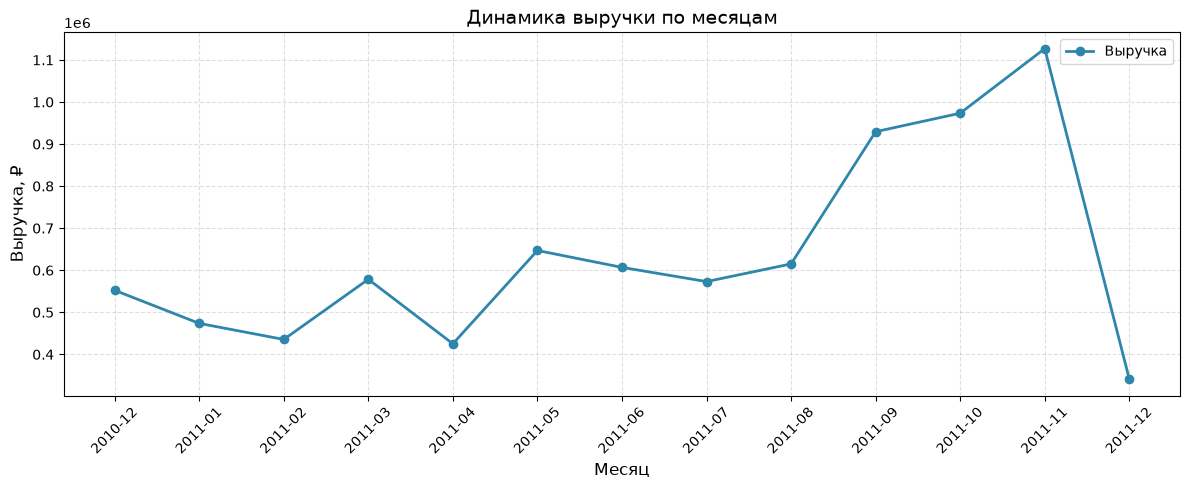

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))  # чуть шире
plt.plot(
    monthly['YearMonth_str'],
    monthly['renevue'],
    marker='o',
    linewidth=2,          # линия потолще
    color='#2E86AB',      # приятный цвет
    label='Выручка'
)
plt.title('Динамика выручки по месяцам', fontsize=14)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Выручка, ₽', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()               # легенда (если будет несколько линий)
plt.tight_layout()
plt.show()


In [6]:
monthly = (
    df.groupby(df['InvoiceDate'].dt.to_period('M'))
      .agg(
          revenue=('TotalPrice', 'sum'),
          n_invoices=('InvoiceNo', 'nunique')  # уникальные номера чеков
      )
      .reset_index()
)

monthly['YearMonth_str'] = monthly['InvoiceDate'].astype(str)  # превращаем Period в строку для подписей
print(monthly.head())


  InvoiceDate     revenue  n_invoices YearMonth_str
0     2010-12  552372.860        1708       2010-12
1     2011-01  473731.900        1236       2011-01
2     2011-02  435534.070        1202       2011-02
3     2011-03  578576.210        1619       2011-03
4     2011-04  425222.671        1384       2011-04


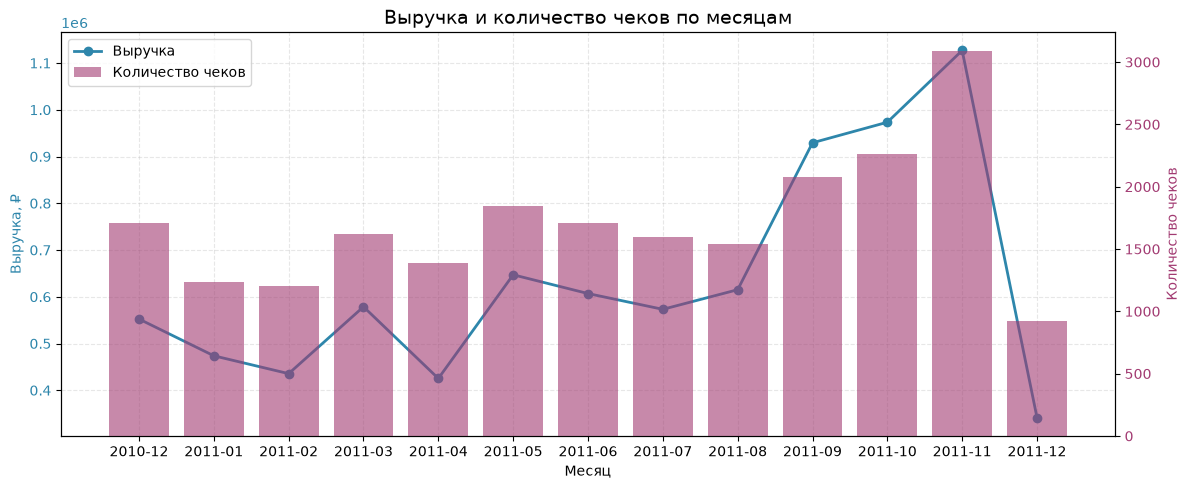

In [7]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 5))

# Левая ось — выручка (линия)
color_rev = '#2E86AB'
ax1.plot(monthly['YearMonth_str'], monthly['revenue'], marker='o', color=color_rev, linewidth=2, label='Выручка')
ax1.set_xlabel('Месяц')
ax1.set_ylabel('Выручка, ₽', color=color_rev)
ax1.tick_params(axis='y', labelcolor=color_rev)

# Правая ось — количество чеков (столбцы)
ax2 = ax1.twinx()
color_inv = '#A23B72'
ax2.bar(monthly['YearMonth_str'], monthly['n_invoices'], color=color_inv, alpha=0.6, label='Количество чеков')
ax2.set_ylabel('Количество чеков', color=color_inv)
ax2.tick_params(axis='y', labelcolor=color_inv)

ax1.set_title('Выручка и количество чеков по месяцам', fontsize=14)
ax1.grid(True, linestyle='--', alpha=0.3)
plt.xticks(rotation=45)

# Объединяем легенды
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.tight_layout()
plt.show()


In [21]:
df['InvoiceDate'].max()

Timestamp('2011-12-09 12:50:00')

Декабрь 2011 года не полный, его не учитываем при анализе

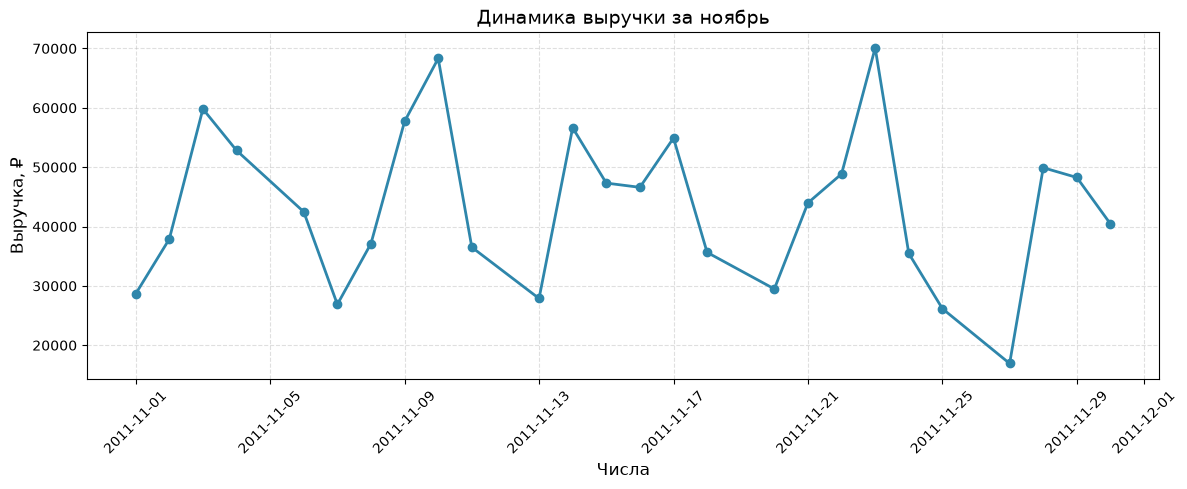

In [8]:
nov = df[(df['YearMonth'] == '2011-11')]
daily_nov = nov.groupby(nov['InvoiceDate'].dt.date)['TotalPrice'].sum()
# Выручка по дням ноября — ищем всплески на конкретных датах
plt.figure(figsize=(12, 5))  # чуть шире
plt.plot(
    daily_nov.index,
    daily_nov.values,
    marker='o',
    linewidth=2,          # линия потолще
    color='#2E86AB',      # приятный цвет
    label='Выручка за ноябрь'
)
plt.title('Динамика выручки за ноябрь', fontsize=14)
plt.xlabel('Числа', fontsize=12)
plt.ylabel('Выручка, ₽', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [9]:
top_invoices = nov.groupby('InvoiceNo')['TotalPrice'].sum()
nov_revenue = nov['TotalPrice'].sum()
print(f"Выручка ноября: {nov_revenue:,.0f}")
print(f"Доля топ-5 счетов: {top_invoices.nlargest(5).sum() / nov_revenue:.1%}")
print(top_invoices.nlargest(5))

Выручка ноября: 1,126,815
Доля топ-5 счетов: 3.8%
InvoiceNo
578305    10584.77
576339     8425.54
575508     8111.20
579196     8107.72
578140     7952.68
Name: TotalPrice, dtype: float64


In [10]:
top_rows = (
    nov[nov['InvoiceNo'].isin(top_codes)]
    [['InvoiceNo', 'Quantity', 'UnitPrice', 'CustomerID', 'Description']]
    .head(150))
print(top_rows)


NameError: name 'top_codes' is not defined

Ноябрь 2011: резкий рост выручки и количества заказов.
Доля крупных счетов (топ‑5) в выручке ноября — 3,8%. Это низкий показатель: всплеск вызван массовым спросом, а не единичными оптовыми заказами.
Сезонность по одному году подтвердить нельзя, но картина согласуется с предрождественским ростом спроса в UK‑ритейле.
Декабрь 2011 исключён из выводов: данные неполные (последняя дата 9 декабря).
Чёрная пятница (25 ноября) как единственная причина пика не подтверждается: рост распределён по месяцу, нет точечного всплеска на одну дату.

In [11]:
top_products = (
    df.groupby(['StockCode', 'Description'])
      .agg(
          TotalPrice=('TotalPrice', 'sum'),
          Quantity=('Quantity', 'sum')
      )
      .reset_index()
      .sort_values('TotalPrice', ascending=False)
)

print(top_products.head(15))


     StockCode                         Description  TotalPrice  Quantity
1322     22423            REGENCY CAKESTAND 3 TIER   132567.70     11529
3475    85123A  WHITE HANGING HEART T-LIGHT HOLDER    93767.80     34128
3460    85099B             JUMBO BAG RED RETROSPOT    83056.52     44963
2805     47566                       PARTY BUNTING    67628.43     15015
3915      POST                             POSTAGE    66710.24      3002
3288     84879       ASSORTED COLOUR BIRD ORNAMENT    56331.91     35215
2010     23084                  RABBIT NIGHT LIGHT    51042.84     27045
2967     79321                       CHILLI LIGHTS    45915.41      9566
1005     22086     PAPER CHAIN KIT 50'S CHRISTMAS     41423.78     15138
1397     22502      PICNIC BASKET WICKER 60 PIECES    39619.50        61
385      21137            BLACK RECORD COVER FRAME    38990.63     11386
1289     22386             JUMBO BAG PINK POLKADOT    36437.78     19692
2266     23298                      SPOTTY BUNTING 

In [12]:
# 1. Смотрим, какие "не-товары" вообще есть в данных
service_codes = df[df['Description'].str.contains('POSTAGE|DOT|MANUAL|DISCOUNT|GIFT', case=False, na=False)]
print(service_codes['StockCode'].value_counts().head(10))

# 2. Исключаем их из товарного рейтинга (но НЕ из данных!)
non_products = service_codes['StockCode'].unique()
top_products_no_service = (
    df[~df['StockCode'].isin(non_products)]
      .groupby(['StockCode', 'Description'])
        .agg(
            TotalPrice=('TotalPrice', 'sum'),
            Quantity=('Quantity', 'sum'),
            UnitPrice=('UnitPrice', 'first')
        )
      .reset_index()
      .sort_values('TotalPrice', ascending=False)
)

print(top_products_no_service.head(10))


StockCode
POST      1196
22384      961
22386      897
22356      511
M          460
84997D     430
21121      342
22585      334
21122      313
84997C     310
Name: count, dtype: int64
     StockCode                         Description  TotalPrice  Quantity  \
1242     22423            REGENCY CAKESTAND 3 TIER   132567.70     11529   
3345    85123A  WHITE HANGING HEART T-LIGHT HOLDER    93767.80     34128   
3330    85099B             JUMBO BAG RED RETROSPOT    83056.52     44963   
2688     47566                       PARTY BUNTING    67628.43     15015   
3169     84879       ASSORTED COLOUR BIRD ORNAMENT    56331.91     35215   
1914     23084                  RABBIT NIGHT LIGHT    51042.84     27045   
2850     79321                       CHILLI LIGHTS    45915.41      9566   
943      22086     PAPER CHAIN KIT 50'S CHRISTMAS     41423.78     15138   
1317     22502      PICNIC BASKET WICKER 60 PIECES    39619.50        61   
368      21137            BLACK RECORD COVER FRAME    

In [13]:
total_revenue = df['TotalPrice'].sum()
top10_revenue = top_products_no_service['TotalPrice'].head(10).sum()
print(f" Доля топ-10 товаров: {top10_revenue/total_revenue:.1%}")

 Доля топ-10 товаров: 7.9%


In [14]:
country_stats = (
    df.groupby('Country')
    .agg(
        revenue=('TotalPrice', 'sum'),
        customers=('CustomerID', 'nunique'),
        order=('InvoiceNo', 'nunique')
    )
    .reset_index()
    .sort_values('revenue', ascending=False)
)
print(country_stats.head(15))

            Country      revenue  customers  order
35   United Kingdom  6747156.154       3950  19857
23      Netherlands   284661.540          9    101
10             EIRE   250001.780          3    319
14          Germany   221509.470         95    603
13           France   196626.050         87    458
0         Australia   137009.770          9     69
32      Switzerland    55739.400         21     71
30            Spain    54756.030         31    105
3           Belgium    40910.960         25    119
31           Sweden    36585.410          8     46
19            Japan    35340.620          8     28
24           Norway    35163.460         10     40
26         Portugal    28995.760         19     70
12          Finland    22326.740         12     48
6   Channel Islands    20076.390          9     33


In [15]:

country_stats_2 = (
    df.groupby('Country')
      .agg(
          revenue=('TotalPrice', 'sum'),
          customers=('CustomerID', 'nunique'),
          orders=('InvoiceNo', 'nunique'),
          items=('Quantity', 'sum')
      )
      .assign(
          avg_order_value=lambda x: x['revenue'] / x['orders'],
          revenue_per_customer=lambda x: x['revenue'] / x['customers']
      )
      .reset_index()
      .sort_values('revenue', ascending=False)
)

print(country_stats_2.head(15))

            Country      revenue  customers  orders    items  avg_order_value  \
35   United Kingdom  6747156.154       3950   19857  3994870       339.787287   
23      Netherlands   284661.540          9     101   200128      2818.431089   
10             EIRE   250001.780          3     319   136187       783.704639   
14          Germany   221509.470         95     603   117341       367.345721   
13           France   196626.050         87     458   109806       429.314520   
0         Australia   137009.770          9      69    83643      1985.648841   
32      Switzerland    55739.400         21      71    29778       785.061972   
30            Spain    54756.030         31     105    26817       521.486000   
3           Belgium    40910.960         25     119    23152       343.789580   
31           Sweden    36585.410          8      46    35632       795.335000   
19            Japan    35340.620          8      28    25218      1262.165000   
24           Norway    35163

In [16]:
# Средняя цена в топ-10
top10 = top_products_no_service.head(10)
top10['UnitPrice_avg'] = top10['TotalPrice'] / top10['Quantity']  # если есть колонка Quantity в агрегации
print(top10[['Description', 'TotalPrice', 'UnitPrice_avg']])


                             Description  TotalPrice  UnitPrice_avg
1242            REGENCY CAKESTAND 3 TIER   132567.70      11.498630
3345  WHITE HANGING HEART T-LIGHT HOLDER    93767.80       2.747533
3330             JUMBO BAG RED RETROSPOT    83056.52       1.847219
2688                       PARTY BUNTING    67628.43       4.504058
3169       ASSORTED COLOUR BIRD ORNAMENT    56331.91       1.599657
1914                  RABBIT NIGHT LIGHT    51042.84       1.887330
2850                       CHILLI LIGHTS    45915.41       4.799855
943      PAPER CHAIN KIT 50'S CHRISTMAS     41423.78       2.736410
1317      PICNIC BASKET WICKER 60 PIECES    39619.50     649.500000
368             BLACK RECORD COVER FRAME    38990.63       3.424436


/tmp/ipykernel_364/3047535930.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top10['UnitPrice_avg'] = top10['TotalPrice'] / top10['Quantity']  # если есть колонка Quantity в агрегации


In [17]:
print(top10['UnitPrice_avg'].sum()/10)

68.45451274590962


In [18]:
# Считаем среднее количество заказов на клиента по странам
country_stats_2['avg_orders_per_customer'] = (
    country_stats_2['orders'] / country_stats_2['customers']
)
print(country_stats_2[['Country', 'revenue', 'customers', 'avg_orders_per_customer']].sort_values('revenue', ascending=False).head(15))


            Country      revenue  customers  avg_orders_per_customer
35   United Kingdom  6747156.154       3950                 5.027089
23      Netherlands   284661.540          9                11.222222
10             EIRE   250001.780          3               106.333333
14          Germany   221509.470         95                 6.347368
13           France   196626.050         87                 5.264368
0         Australia   137009.770          9                 7.666667
32      Switzerland    55739.400         21                 3.380952
30            Spain    54756.030         31                 3.387097
3           Belgium    40910.960         25                 4.760000
31           Sweden    36585.410          8                 5.750000
19            Japan    35340.620          8                 3.500000
24           Norway    35163.460         10                 4.000000
26         Portugal    28995.760         19                 3.684211
12          Finland    22326.740  

Доля топ‑10 товаров в выручке — 7.9%, что указывает на отсутствие «одного главного хита». Выручка формируется за счёт широкого ассортимента, где преобладают недорогие позиции с высокой оборачиваемостью. Средняя цена товара в топ‑10 — 68 £.
Великобритания обеспечивает более 51% выручки, подтверждая локальную ориентацию магазина.
За пределами UK выручка формируется преимущественно B2B‑клиентами: показатель «заказов на клиента» в топ‑странах значительно выше, чем в UK. Это говорит о модели оптовых продаж, а не массового розничного спроса.
Исключены из анализа «не‑товары» (POSTAGE, Manual, Discount и т. п.) — они не отражают товарный ассортимент и могут искажать выводы по выручке.


In [19]:
pd.Series(non_products, name='excluded_stock_code').to_csv('excluded_service_codes.csv', index=False)


In [20]:
top10 = top_products_no_service.head(10).copy()

top_codes = top10['StockCode'].tolist()
detail = df[df['StockCode'].isin(top_codes)]

median_price = detail.groupby('StockCode')['UnitPrice'].median()
print(median_price.sort_values(ascending=False))

suspicious = top10[top10['UnitPrice'] > 100]
print(suspicious)

code = suspicious['StockCode'].iloc[0]
print(df[df['StockCode'] == code][['Quantity', 'UnitPrice', 'InvoiceDate']].describe())
print(df[df['StockCode'] == code][['InvoiceNo', 'Quantity', 'UnitPrice', 'CustomerID']].sort_values('TotalPrice', ascending=False).head(5))

StockCode
22423     12.75
22502      5.95
79321      5.75
47566      4.95
21137      3.75
22086      2.95
85123A     2.95
23084      2.08
85099B     2.08
84879      1.69
Name: UnitPrice, dtype: float64
     StockCode                     Description  TotalPrice  Quantity  \
1317     22502  PICNIC BASKET WICKER 60 PIECES     39619.5        61   

      UnitPrice  
1317      649.5  
         Quantity   UnitPrice                    InvoiceDate
count  245.000000  245.000000                            245
mean     5.755102   11.060816  2011-03-28 23:56:39.428571648
min    -60.000000    2.000000            2010-12-01 10:29:00
25%      2.000000    5.950000            2011-02-10 10:18:00
50%      4.000000    5.950000            2011-04-04 12:07:00
75%      4.000000    5.950000            2011-05-06 15:47:00
max     96.000000  649.500000            2011-09-25 14:33:00
std     11.238711   58.040415                            NaN


KeyError: 'TotalPrice'

In [26]:
import os

monthly_export = (
    monthly.sort_values('YearMonth')
        [['YearMonth_str', 'revenue', 'orders', 'customers', 'items']]
)
monthly_export.to_csv('monthly_metrics.csv', index=False, encoding='utf-8-sig', decimal=',')

top_products_no_service.to_csv('top_products.csv', index=False, encoding='utf-8-sig', decimal=',')

country_stats.to_csv('country_stats.csv', index=False, encoding='utf-8-sig', decimal=',')

for f in ['monthly_metrics.csv', 'top_products.csv', 'country_stats.csv']:
    print(f, os.path.getsize(f), 'байт')
    print(pd.read_csv(f, decimal=',').head(2))

monthly_metrics.csv 532 байт
  YearMonth_str    revenue  orders  customers   items
0       2010-12  552372.86    1708        948  295177
1       2011-01  473731.90    1236        783  268755
top_products.csv 215827 байт
  StockCode                         Description  TotalPrice  Quantity  \
0     22423            REGENCY CAKESTAND 3 TIER    132567.7     11529   
1    85123A  WHITE HANGING HEART T-LIGHT HOLDER     93767.8     34128   

   UnitPrice  
0      10.95  
1       2.55  
country_stats.csv 975 байт
          Country      revenue  customers  order
0  United Kingdom  6747156.154       3950  19857
1     Netherlands   284661.540          9    101
